In [1]:
import os 
import numpy as np
import pandas as pd
from tqdm import tqdm
from pathlib import Path
import pickle
import anndata
from anndata import AnnData
import anndata as ad
from pathlib import Path
from collections import defaultdict
from datetime import datetime
import matplotlib.pyplot as plt

In [2]:
def pickle_data(data, path):

    with open(path, "wb") as f:
        pickle.dump(data, f)

def load_pickle(path): 

    with open(path, "rb") as f: 
        return pickle.load(f)

### Examine Hartwig RNA

In [5]:
example_rna_data = pd.read_csv('/data/rbg/shared/datasets/Hartwig/isofox_tpm_update_4/raw/H00009481.isf.transcript_data.csv')
example_rna_data.head()

,GeneId,GeneName,TransId,TransName,ExonCount,TranscriptLength,EffectiveLength,FittedFragments,RawFittedFragments,AdjTPM,RawTPM,TranscriptBasesCovered,SJSupported,UniqueSJSupported,UniqueSJFragments,UniqueNonSJFragments,DiscordantFragments,LowMapQualFrags
0,ENSG00000206906,RNU6-458P,306860,ENST00000384179,1,107,22,0.0,0.0,0.00000,0.00000,0,0,0,0,0,0,0.0
1,ENSG00000257356,BNIP3P6,283078,ENST00000549284,1,499,285,0.0,0.0,0.00000,0.00000,0,0,0,0,0,0,0.0
2,ENSG00000257115,OR11H12,396923,ENST00000550708,1,981,759,1.0,1.0,0.07904,0.02875,203,0,0,0,0,0,0.0
3,ENSG00000258233,ARHGAP42P5,283890,ENST00000548856,1,2936,2714,0.0,0.0,0.00000,0.00000,0,0,0,0,0,0,0.0
4,ENSG00000257504,LINC02297,292415,ENST00000548050,3,1493,1271,0.0,0.0,0.00000,0.00000,0,0,0,0,0,0,0.0


In [6]:
gene_id_to_symbol = dict(zip(example_rna_data['GeneId'], example_rna_data['GeneName']))

In [7]:
import requests

def get_protein_coding_genes(gene_id_to_symbol, batch_size=1000):
    url = "https://rest.ensembl.org/lookup/id"
    headers = {"Content-Type": "application/json", "Accept": "application/json"}
    
    gene_ids = list(gene_id_to_symbol.keys())
    protein_coding = []
    
    for i in tqdm(range(0, len(gene_ids), batch_size)):
        batch = gene_ids[i:i+batch_size]
        response = requests.post(url, headers=headers, json={"ids": batch})
        data = response.json()
        
        protein_coding += [
            gene_id_to_symbol[gid]
            for gid, info in data.items()
            if isinstance(info, dict) and info.get("biotype") == "protein_coding"
        ]
    
    return protein_coding

In [8]:
protein_coding_genes = get_protein_coding_genes(gene_id_to_symbol)

100%|██████████| 40/40 [05:29<00:00,  8.23s/it]


In [9]:
len(protein_coding_genes)

19374

In [5]:
# in example_rna_data get value in AdjTPM column for gene 'PAX8'
pax8_tpm = example_rna_data[example_rna_data['GeneName'] == 'PAX8']['AdjTPM'].sum()
print(f"PAX8 TPM in H00009481: {pax8_tpm}")

PAX8 TPM in H00009481: 3.0838644807441855


In [6]:
gene_names = example_rna_data['GeneName'].unique()
len(gene_names)

39500

### Process Hartwig RNA

In [7]:
def load_tcga_gene_symbols(pkl_path: str) -> list[str]:
    with open(pkl_path, "rb") as f:
        genes = pickle.load(f)
    genes = list(genes)
    if not genes:
        raise ValueError(f"Empty gene list in {pkl_path}")
    return [str(g) for g in genes]


def list_patient_files(raw_dir: str) -> list[Path]:
    files = sorted(Path(raw_dir).glob("*.isf.transcript_data.csv"))
    if not files:
        raise FileNotFoundError(f"No *.isf.transcript_data.csv files found in {raw_dir}")
    return files

def patient_id_from_filename(fp: Path) -> str:
    return fp.name.replace(".isf.transcript_data.csv", "")

In [9]:
def load_symbol_level_tpm_filtered(
    csv_path: Path,
    tpm_col: str = "AdjTPM",
) -> pd.Series:
    """
    Returns Series indexed by gene SYMBOL, summing TPM across transcripts,
    filtered to allowed_symbols.
    """
    df = pd.read_csv(csv_path, usecols=["GeneName", tpm_col])
    df = df.dropna(subset=["GeneName"]).copy()
    df["GeneName"] = df["GeneName"].astype(str)

    if df.empty:
        return pd.Series(dtype=float)

    sym_tpm = df.groupby("GeneName", sort=False)[tpm_col].sum()
    sym_tpm = pd.to_numeric(sym_tpm, errors="coerce").fillna(0.0)
    return sym_tpm

In [10]:
def build_hartwig_filtered_anndata_unordered(
    raw_dir: str,
    tpm_col: str = "AdjTPM",
    verbose_every: int = 25,
) -> ad.AnnData:
    files = list_patient_files(raw_dir)

    print(f"Found {len(files)} patients")
    print(f"Using TPM column: {tpm_col}")

    # Pass 1: read each patient, store filtered series, collect union genes
    patient_ids = []
    series_by_patient = []
    gene_union = set()

    for i, fp in tqdm(enumerate(files)):
        pid = patient_id_from_filename(fp)
        patient_ids.append(pid)

        s = load_symbol_level_tpm_filtered(fp, tpm_col=tpm_col)
        series_by_patient.append(s)
        gene_union.update(s.index.tolist())

        if verbose_every and (i + 1) % verbose_every == 0:
            print(f"[{i+1}/{len(files)}] processed; genes matched this sample: {len(s)}")

    gene_list = sorted(gene_union)  # ordering arbitrary
    print(f"Genes retained (TCGA and Hartwig): {len(gene_list)}")

    sym_to_col = {g: j for j, g in enumerate(gene_list)}
    X = np.zeros((len(files), len(gene_list)), dtype=np.float32)

    for i, s in enumerate(series_by_patient):
        row = X[i]
        for sym, val in s.items():
            row[sym_to_col[sym]] = float(val)

    obs = pd.DataFrame({"patient_id": patient_ids}, index=patient_ids)
    var = pd.DataFrame(index=gene_list)
    var["gene_symbol"] = gene_list

    # log_variance on log1p(TPM)
    X_log = np.log1p(X)
    var["log_variance"] = np.var(X_log, axis=0)

    adata = ad.AnnData(X=X, obs=obs, var=var)
    adata.obs_names.name = "patient_id"
    adata.var_names.name = "gene_symbol"

    print(f"Final shape: {adata.shape}")
    return adata

In [ ]:
raw_dir = "/data/rbg/shared/datasets/Hartwig/isofox_tpm_update_4/raw"

adata = build_hartwig_filtered_anndata_unordered(
    raw_dir=raw_dir,
    tpm_col="AdjTPM",
)

print(adata)

In [3]:
adata = ad.read_h5ad("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/RNA/Hartwig_bulk_RNA_processed.h5ad")

In [10]:
# Get gene ordering
hartwig_var = dict(zip(adata.var["gene_symbol"], adata.var["log_variance"]))

# Filter the dictionary to keep only genes in hartwig_genes
hartwig_var = {gene: var for gene, var in hartwig_var.items() if gene in protein_coding_genes}

# Sort the dictionary by value (variance) in descending order
selected_genes_Hartwig = dict(
    sorted(hartwig_var.items(), key=lambda item: item[1], reverse=True)
)

In [11]:
len(selected_genes_Hartwig)

18005

In [12]:
pickle_data(selected_genes_Hartwig, "/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/Hartwig_genes_ordered_by_variance.pkl")

### Sanity checks

In [13]:
print(adata)
print("dtype:", adata.X.dtype)
print("Any NaNs in X?", np.isnan(adata.X).any())
print("Any inf in X?", np.isinf(adata.X).any())

AnnData object with n_obs × n_vars = 2644 × 28052
    obs: 'patient_id'
    var: 'gene_symbol', 'log_variance'
dtype: float32
Any NaNs in X? False
Any inf in X? False


In [14]:
print("Max value:", adata.X.max())
print("Mean sample sum:", np.mean(np.sum(adata.X, axis=1)))
print("Median sample sum:", np.median(np.sum(adata.X, axis=1)))

Max value: 1.82e+07
Mean sample sum: 4.1866418e+06
Median sample sum: 3.525039e+06


In [15]:
nonzero_per_sample = (adata.X > 0).sum(axis=1)
print("Median nonzero genes per sample:", np.median(nonzero_per_sample))
print("Min:", nonzero_per_sample.min())
print("Max:", nonzero_per_sample.max())

Median nonzero genes per sample: 24272.0
Min: 18527
Max: 25947


In [16]:
zero_var = (adata.var["log_variance"] < -20).sum()
print("Genes with near-zero variance:", zero_var)

Genes with near-zero variance: 0


In [17]:
raw_var = adata.X.var(axis=0)
print("Genes with zero raw variance:", (raw_var == 0).sum())

Genes with zero raw variance: 0


In [18]:
lv = adata.var["log_variance"].values
print("Min:", lv.min())
print("Median:", np.median(lv))
print("Max:", lv.max())

Min: 0.009330799
Median: 0.257539
Max: 10.274012


In [19]:
print("Duplicate gene symbols:",
      adata.var_names.duplicated().sum())

Duplicate gene symbols: 0


In [20]:
from scipy.stats import pearsonr

r, _ = pearsonr(adata.X[0], adata.X[1])
print("Sample 0 vs 1 correlation:", r)

Sample 0 vs 1 correlation: 0.9883932


### Cleaned way to build clinical labels

In [3]:
# Load data
treatment_path = "/data/rbg/shared/datasets/Hartwig/isofox_tpm_update_4/treatment_responses.tsv"
metadata_path = "/data/rbg/shared/datasets/Hartwig/isofox_tpm_update_4/metadata.tsv"

treatments = pd.read_csv(treatment_path, sep="\t")
metadata = pd.read_csv(metadata_path, sep="\t")

In [4]:
# Merge biopsy dates into treatment records
df = treatments.merge(metadata[["sampleId", "biopsyDate", "deathDate"]], on="sampleId", how="left")

In [5]:
df["startDate"] = pd.to_datetime(df["startDate"], errors="coerce")
df["responseDate"] = pd.to_datetime(df["responseDate"], errors="coerce")
df["biopsyDate"] = pd.to_datetime(df["biopsyDate"], errors="coerce")
df["deathDate"] = pd.to_datetime(df["deathDate"], errors="coerce")

In [6]:
def get_response_dict(df):
    """
    Returns {sampleId: 0 or 1}
    Criteria: 1 if the patient had a PR or CR on the NEXT treatment after biopsy.
    """
    response_dict = {}
    # Only consider rows with a valid clinical response
    valid_evals = df.dropna(subset=["response"]).copy()
    
    # Filter for treatments starting AFTER biopsy
    valid_evals = valid_evals[valid_evals["startDate"] >= valid_evals["biopsyDate"]]

    for sid, group in valid_evals.groupby("sampleId"):
        # Focus only on the first treatment line after biopsy
        first_treatment_date = group["startDate"].min()
        target_treatment = group[group["startDate"] == first_treatment_date]
        
        # 1 if ANY evaluation in this treatment was CR or PR
        is_responder = int(target_treatment["response"].isin(["CR", "PR"]).any())
        response_dict[sid] = is_responder
        
    return response_dict

In [7]:
def get_ttp_dict(df):
    """
    Returns {sampleId: {'time': days, 'event': 0 or 1}}
    Criteria: 
    - Event (1) if 'PD' occurs.
    - Censored (0) at the last known responseDate if no 'PD' occurs.
    """
    ttp_dict = {}
    # For survival, need at least a startDate and a responseDate
    survival_df = df.dropna(subset=["startDate", "responseDate"]).copy()
    survival_df = survival_df[survival_df["startDate"] >= survival_df["biopsyDate"]]

    for sid, group in survival_df.groupby("sampleId"):
        # Select the first treatment line after biopsy
        first_treatment_date = group["startDate"].min()
        target_treatment = group[group["startDate"] == first_treatment_date].sort_values("responseDate")
        
        # Look for Progression (PD)
        pd_rows = target_treatment[target_treatment["response"] == "PD"]
        
        if not pd_rows.empty:
            # EVENT: First PD date - treatment start
            first_pd_date = pd_rows["responseDate"].iloc[0]
            time = (first_pd_date - first_treatment_date).days
            event = 1
        else:
            # CENSORED: Last known evaluation date - treatment start
            last_eval_date = target_treatment["responseDate"].max()
            time = (last_eval_date - first_treatment_date).days
            event = 0
            
        # Only store if the timing is non-negative
        if time >= 0:
            ttp_dict[sid] = {"time": time, "event": event}
            
    return ttp_dict

In [8]:
def get_PFS_dict(df):
    """
    Returns {sampleId: {'time': days, 'event': 1 (PD or Death) or 0 (Censored)}}
    """
    pfs_dict = {}
    
    # Filter for treatments starting AFTER biopsy
    # We drop rows with missing startDate as we can't anchor the timeline
    survival_df = df.dropna(subset=["startDate"]).copy()
    survival_df = survival_df[survival_df["startDate"] >= survival_df["biopsyDate"]]

    for sid, group in survival_df.groupby("sampleId"):
        # Select the first treatment line after biopsy
        first_treatment_date = group["startDate"].min()
        target_treatment = group[group["startDate"] == first_treatment_date].sort_values("responseDate")
        
        # Patient-level death date (metadata is constant across the group)
        death_date = target_treatment["deathDate"].iloc[0]
        
        # 1. Look for Progression (PD)
        pd_rows = target_treatment[target_treatment["response"] == "PD"]
        first_pd_date = pd_rows["responseDate"].min() if not pd_rows.empty else pd.NaT
        
        # 2. Compare PD and Death to find the earliest event
        # If both are NaT, event_dates will be empty
        event_candidates = [d for d in [first_pd_date, death_date] if pd.notna(d)]
        
        if event_candidates:
            # EVENT: Use the earliest date among PD and Death
            event_date = min(event_candidates)
            time = (event_date - first_treatment_date).days
            event = 1
        else:
            # CENSORED: No PD and no Death date recorded
            # Use the latest clinical evaluation date as the censoring point
            last_eval_date = target_treatment["responseDate"].max()
            if pd.notna(last_eval_date):
                time = (last_eval_date - first_treatment_date).days
                event = 0
            else:
                # If no responseDate is available, we can't reliably censor
                continue 
            
        if time >= 0:
            pfs_dict[sid] = {"time": time, "event": event}
            
    return pfs_dict

In [9]:
# Get Labels
responses = get_response_dict(df)
ttp_durations = get_ttp_dict(df)
pfs_durations = get_PFS_dict(df)


print("Sample IDs with response labels:", len(responses))
print("Sample IDs with TTP labels:", len(ttp_durations))
print("Sample IDs with PFS labels:", len(pfs_durations))

Sample IDs with response labels: 5212
Sample IDs with TTP labels: 5212
Sample IDs with PFS labels: 6230


In [10]:
len(set(responses.keys()).intersection(set(pfs_durations.keys())))

5201

In [11]:
adata = ad.read_h5ad("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/RNA/Hartwig_bulk_RNA_processed_log1p.h5ad")

In [12]:
rna_samples = set(adata.obs_names)

rna_samples_with_response = rna_samples.intersection(set(responses.keys()))
rna_samples_with_ttp = rna_samples.intersection(set(ttp_durations.keys()))
rna_samples_with_pfs = rna_samples.intersection(set(pfs_durations.keys()))

print("RNA samples with response labels:", len(rna_samples_with_response))
print("RNA samples with TTP labels:", len(rna_samples_with_ttp))
print("RNA samples with PFS labels:", len(rna_samples_with_pfs))

RNA samples with response labels: 2232
RNA samples with TTP labels: 2232
RNA samples with PFS labels: 2261


In [13]:
common_samples = rna_samples_with_response.intersection(rna_samples_with_ttp).intersection(rna_samples_with_pfs)

time_mismatch = 0
event_mismatch = 0
for sid in common_samples:
    if ttp_durations[sid]["time"] != pfs_durations[sid]["time"]:
        time_mismatch += 1
    if ttp_durations[sid]["event"] != pfs_durations[sid]["event"]:
        event_mismatch += 1

print(f"Among {len(common_samples)} common samples, TTP vs PFS time mismatch: {time_mismatch}, event mismatch: {event_mismatch}")

Among 2232 common samples, TTP vs PFS time mismatch: 341, event mismatch: 341


In [14]:
# Combine into final label df (has response and ttp)
final_labels = []
for sid in responses.keys():
    if sid in pfs_durations:
        final_labels.append({
            "sampleId": sid,
            "response": responses[sid],
            "time": pfs_durations[sid]["time"],
            "event": pfs_durations[sid]["event"]
        })

label_df = pd.DataFrame(final_labels)
print(f"Final label DataFrame shape: {label_df.shape}")

# Double check there are no nan values or duplicate samples
print("Any NaNs in label_df?", label_df.isna().any().any())
print("Duplicate sampleIds in label_df?", label_df["sampleId"].duplicated().any())

label_df.head()

Final label DataFrame shape: (5201, 4)
Any NaNs in label_df? False
Duplicate sampleIds in label_df? False


,sampleId,response,time,event
0,H00000026,1,78,0
1,H00000027,0,981,1
2,H00000030,0,16,1
3,H00000032,0,104,1
4,H00000034,0,123,1


In [15]:
# Look at overlap of sampleIds between RNA and labels
rna_samples = set(adata.obs_names)
label_samples = set(label_df["sampleId"])
samples_with_rna_and_label = rna_samples.intersection(label_samples)
print("RNA samples:", len(rna_samples))
print(f"Of which have labels:", len(samples_with_rna_and_label))

RNA samples: 2644
Of which have labels: 2232


In [33]:
# Saving
label_df.to_csv("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/clinical_labels.csv", index=False)
pickle_data(samples_with_rna_and_label, "/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/samples_with_RNA_and_labels.pkl")

In [35]:
# Check class imbalance
filtered_labels = label_df[label_df["sampleId"].isin(samples_with_rna_and_label)]
print(f"Filtered label_df shape: {filtered_labels.shape}")
response_counts = filtered_labels["response"].value_counts()

print(response_counts)

Filtered label_df shape: (2232, 4)
response
0    1488
1     744
Name: count, dtype: int64


In [36]:
# Of the samples with RNA and labels, how many unique patients are there? (some patients have multiple samples)
samples_with_rna_and_label = load_pickle("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/samples_with_RNA_and_labels.pkl")
metadata = pd.read_csv("/data/rbg/shared/datasets/Hartwig/isofox_tpm_update_4/metadata.tsv", sep="\t")
metadata = metadata[metadata["sampleId"].isin(samples_with_rna_and_label)]
unique_patients = metadata["patientId"].nunique()
print(f"Unique patients with RNA and labels: {unique_patients}")

Unique patients with RNA and labels: 2153


In [16]:
# Map sampleId to patientId
sample_to_patient = dict(zip(metadata["sampleId"], metadata["patientId"]))
pickle_data(sample_to_patient, "/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/sample_to_patient_mapping.pkl")

### Get cancer type mapping

In [39]:
samples_with_rna_and_label = load_pickle("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/samples_with_RNA_and_labels.pkl")
metadata = pd.read_csv("/data/rbg/shared/datasets/Hartwig/isofox_tpm_update_4/metadata.tsv", sep="\t")

In [40]:
filtered_metadata = metadata[metadata["sampleId"].isin(samples_with_rna_and_label)].copy()
print(f"Length of filtered metadata: {len(filtered_metadata)}")

Length of filtered metadata: 2232


In [41]:
hartwig_to_tcga = {

    # Very clean matches
    "Breast": "BRCA",
    "Colon": "COAD",
    "Rectum": "READ",
    "Lung": "LUAD",  # Hartwig lung is mixed; LUAD is safest single TCGA lung project
    "Skin": "SKCM",
    "Prostate": "PRAD",
    "Pancreas": "PAAD",
    "Ovary": "OV",
    "Bladder": "BLCA",
    "Kidney": "KIRC",  # dominant kidney subtype
    "Liver": "LIHC",
    "Stomach": "STAD",
    "Cervix": "CESC",
    "Thyroid gland": "THCA",
    "Thymus": "THYM",
    "Testis": "TGCT",
    "Adrenal gland": "ACC",
    "Brain/central nervous system": "GBM",

    # GI / hepatobiliary
    "Esophagus/gastroesophageal junction": "ESCA",
    "Biliary tract": "CHOL",
    "Gallbladder": "CHOL",
    "Ampulla of Vater": "CHOL",

    # Urologic
    "Ureter/renal pelvis": "BLCA",  # urothelial lineage
    "Urethra": "BLCA",

    # Gynecologic
    "Endometrium/uterus": "UCEC",
    "Vulva": "CESC",
    "Vagina": "CESC",

    # Head & Neck
    "Oral cavity/tongue": "HNSC",
    "Oropharynx": "HNSC",
    "Larynx": "HNSC",
    "Hypopharynx": "HNSC",
    "Nasopharynx": "HNSC",
    "Nasal cavity": "HNSC",
    "Salivary gland": "HNSC",

    # Other solid
    "Soft tissue": "SARC",
    "Pleura": "MESO",
    "Penis": "CESC",  # closest HPV-driven squamous analog
    "Appendix": "COAD",
    "Anus": "CESC",   # closest HPV-driven squamous analog
}

In [42]:
# Map Hartwig metadata sampleId column to TCGA project based on primaryTumorLocation
filtered_metadata["TCGA_project"] = filtered_metadata["primaryTumorLocation"].map(hartwig_to_tcga, None)

In [43]:
# Create dict mapping, keys are only the sampleIds with non None TCGA project, values are TCGA project
sample_to_tcga = dict(zip(filtered_metadata.dropna(subset=["TCGA_project"])["sampleId"], filtered_metadata.dropna(subset=["TCGA_project"])["TCGA_project"]))

In [44]:
pickle_data(sample_to_tcga, "../../data/Hartwig/id_to_tcga_mapping.pkl")

### Get cohort statistics

In [3]:
samples_with_rna_and_label = load_pickle("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/samples_with_RNA_and_labels.pkl")
metadata = pd.read_csv("/data/rbg/shared/datasets/Hartwig/isofox_tpm_update_4/metadata.tsv", sep="\t")

In [4]:
filtered_metadata = metadata[metadata["sampleId"].isin(samples_with_rna_and_label)].copy()
print(f"Length of filtered metadata: {len(filtered_metadata)}")
filtered_metadata.head()

Length of filtered metadata: 2232


,sampleId,specimenId,patientId,tumorPurity,gender,birthYear,deathDate,primaryTumorLocation,primaryTumorType,primaryTumorExtraDetails,...,hasSystemicPreTreatment,hasRadiotherapyPreTreatment,treatmentGiven,treatmentStartDate,treatmentEndDate,treatment,consolidatedTreatmentType,responseDate,responseMeasured,firstResponse
301,H00009590,S00000264,D00000256,NaN,male,1952.0,NaN,Prostate,Adenocarcinoma,NaN,...,Yes,No,Yes,2015-09-24,2016-04-29,Enzalutamide,Hormonal therapy,2015-10-08,Yes,SD
302,H00009597,S00000163,D00000175,NaN,female,1960.0,NaN,Lung,"Non-small cell carcinoma (NSCLC), not otherwis...",NaN,...,Yes,Yes,Yes,2016-04-13,2017-04-28,Nivolumab,Immunotherapy,2016-07-14,Yes,PR
303,H00009598,S00000290,D00000285,NaN,male,1971.0,NaN,Soft tissue,Synovial sarcoma,NaN,...,No,No,Yes,2016-03-18,2016-07-03,Doxorubicin/Ifosfamide,Chemotherapy,2016-04-21,Yes,SD
304,H00009600,S00000179,D00000181,NaN,female,1969.0,NaN,Breast,Invasive ductal carcinoma of no special type (...,ER-negative/Her2-negative (triple negative),...,Yes,Yes,Yes,2016-04-01,2016-07-27,Gemcitabine/Carboplatin/Paclitaxel,Chemotherapy,2016-06-08,Yes,SD
306,H00009602,S00000257,D00000251,NaN,female,1956.0,NaN,Soft tissue,Gastrointestinal stromal tumor (GIST),NaN,...,Yes,No,Yes,2016-03-16,2016-08-31,Masitinib,Targeted therapy,2016-06-01,Yes,PD


In [7]:
filtered_metadata["primaryTumorLocation"].value_counts()

primaryTumorLocation
Breast                                 468
Colon                                  284
Lung                                   206
Skin                                   197
Prostate                               182
Pancreas                               104
Ovary                                   95
Soft tissue                             93
Bladder                                 83
Esophagus/gastroesophageal junction     78
Kidney                                  71
Cancer of unknown primary (CUP)         60
Small bowel/intestine                   35
Rectum                                  28
Biliary tract                           28
Liver                                   27
Ureter/renal pelvis                     23
Endometrium/uterus                      22
Cervix                                  20
Stomach                                 19
Lymphoid                                14
Pleura                                  13
Gallbladder                      

In [38]:
tumor_location_TCGA_organ_map = {
    # --- Thoracic & Respiratory ---
    "Lung": ["LUAD", "LUSC"],
    "Pleura": ["MESO"],
    "Thymus": ["THYM"],

    # --- Gastrointestinal ---
    "Esophagus/gastroesophageal junction": ["ESCA"],
    "Stomach": ["STAD"],
    "Colon": ["COAD"],
    "Rectum": ["READ"],
    "Liver": ["LIHC"],
    "Biliary tract": ["CHOL"],
    "Pancreas": ["PAAD"],

    # --- Genitourinary ---
    "Bladder": ["BLCA"],
    "Kidney": ["KIRC", "KIRP", "KICH"],
    "Prostate": ["PRAD"],
    "Testis": ["TGCT"],

    # --- Gynecologic ---
    "Breast": ["BRCA"],
    "Ovary": ["OV"],
    "Endometrium/uterus": ["UCEC", "UCS"],
    "Cervix": ["CESC"],

    # --- Head and Neck ---
    "Oral cavity/tongue": ["HNSC"],
    "Oropharynx": ["HNSC"],
    "Larynx": ["HNSC"],
    "Hypopharynx": ["HNSC"],
    "Nasopharynx": ["HNSC"],
    "Nasal cavity": ["HNSC"],

    # --- Endocrine & Others ---
    "Thyroid gland": ["THCA"],
    "Adrenal gland": ["ACC", "PCPG"],
    "Skin": ["SKCM"],
    "Soft tissue": ["SARC"],
    "Brain/central nervous system": ["LGG", "GBM"],
    "Eye": ["UVM"],
    "Lymphoid": ["DLBC"]
}

In [43]:
sample_to_cancer_type_map = {}

unknown_locations = set()
ambiguous_locations = []
unmapped_locations = []

for sample in samples_with_rna_and_label:
    location = filtered_metadata[filtered_metadata["sampleId"] == sample]["primaryTumorLocation"].iloc[0]
    tcga_types = tumor_location_TCGA_organ_map.get(location, ["Unmapped"])
    
    if location == "Unknown":
        unknown_locations.add(sample)
    elif len(tcga_types) > 1:
        ambiguous_locations.append([sample, location, tcga_types])
    elif tcga_types == ["Unmapped"]:
        unmapped_locations.append([sample, location])
    else:
        sample_to_cancer_type_map[sample] = tcga_types

In [45]:
# Print summary
print(f"Total samples with RNA and labels: {len(samples_with_rna_and_label)}")
print(f"Samples with mapped tumor location: {len(sample_to_cancer_type_map)}")
print(f"Samples with unknown tumor location: {len(unknown_locations)}")
print(f"Samples with ambiguous tumor location: {len(ambiguous_locations)}")
print(f"Samples with unmapped tumor location: {len(unmapped_locations)}")

Total samples with RNA and labels: 2232
Samples with mapped tumor location: 1760
Samples with unknown tumor location: 7
Samples with ambiguous tumor location: 301
Samples with unmapped tumor location: 164


In [24]:
# Make ambiguous locations a dataframe
ambiguous_df = pd.DataFrame(ambiguous_locations, columns=["sampleId", "tumorLocation", "possibleTCGAtypes"])

# Get value counts of tumor location
ambiguous_df["tumorLocation"].value_counts()

tumorLocation
Lung                            206
Kidney                           71
Endometrium/uterus               22
Adrenal gland                     1
Brain/central nervous system      1
Name: count, dtype: int64

In [32]:
hartwig_tumor_type_to_tcga = load_pickle("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/hartwig_to_tcga_cancer_mapping.pkl")
hartwig_tumor_type_to_tcga

{'Gastrointestinal stromal tumor (GIST)': 'SARC',
 'Undifferentiated (pleomorphic or spindle cell) sarcoma/sarcoma NOS': 'SARC',
 'Synovial sarcoma': 'SARC',
 'Leiomyosarcoma': 'SARC',
 'Myxofibrosarcoma': 'SARC',
 'Angiosarcoma': 'SARC',
 'Liposarcoma, dedifferentiated': 'SARC',
 'Liposarcoma, not otherwise specified': 'SARC',
 'Liposarcoma, myxoid/round cell': 'SARC',
 'Liposarcoma, pleomorphic': 'SARC',
 'Epithelioid sarcoma': 'SARC',
 'Ewing sarcoma': 'SARC',
 'Solitary fibrous tumor': 'SARC',
 'Osteosarcoma': 'SARC',
 'Sclerosing epithelioid fibrosarcoma': 'SARC',
 'Alveolar soft part sarcoma': 'SARC',
 'Desmoplastic small round cell tumor': 'SARC',
 'Malignant Peripheral Nerve Sheath Tumor (MPNST)': 'SARC',
 'Low-grade myofibroblastic sarcoma': 'SARC',
 'Low-grade fibromyxoid sarcoma': 'SARC',
 'Clear cell sarcoma': 'SARC',
 'Intimal sarcoma': 'SARC',
 'Chondrosarcoma': 'SARC',
 'Inflammatory myofibroblastic tumor': 'SARC',
 'Invasive ductal carcinoma of no special type (NST)': '

In [34]:
# Second round: use primaryTumorType mapping
unmapped_samples = set()
newly_mapped_samples = {}
for sample in samples_with_rna_and_label:
    if sample in sample_to_cancer_type_map:
        continue  # already mapped by location
    primary_type = filtered_metadata[filtered_metadata["sampleId"] == sample]["primaryTumorType"].iloc[0]
    tcga_type = hartwig_tumor_type_to_tcga.get(primary_type, None)
    
    if tcga_type is None:
        unmapped_samples.add(sample)
    else:
        newly_mapped_samples[sample] = tcga_type
        
print(f"Newly mapped samples using primaryTumorType: {len(newly_mapped_samples)}")
print(f"Still unmapped samples after primaryTumorType: {len(unmapped_samples)}")

Newly mapped samples using primaryTumorType: 291
Still unmapped samples after primaryTumorType: 77


In [35]:
# Create dataframe for unmapped samples with sampleId, primaryTumorType, and primaryTumorLocation
unmapped_df = pd.DataFrame([
    {
        "sampleId": sample,
        "primaryTumorType": filtered_metadata[filtered_metadata["sampleId"] == sample]["primaryTumorType"].iloc[0],
        "primaryTumorLocation": filtered_metadata[filtered_metadata["sampleId"] == sample]["primaryTumorLocation"].iloc[0]
    }
    for sample in unmapped_samples
])
print(f"Unmapped samples dataframe shape: {unmapped_df.shape}")


Unmapped samples dataframe shape: (77, 3)


,sampleId,primaryTumorType,primaryTumorLocation
0,H00010781,Unknown,Cancer of unknown primary (CUP)
1,H00012514,Unknown,Cancer of unknown primary (CUP)
2,H00010396,Other,Kidney
3,H00012667,Unknown,Cancer of unknown primary (CUP)
4,H00009707,Other,Lung


In [37]:
unmapped_df.to_csv("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/samples_with_unmapped_TCGA_cancer_type.csv", index=False)

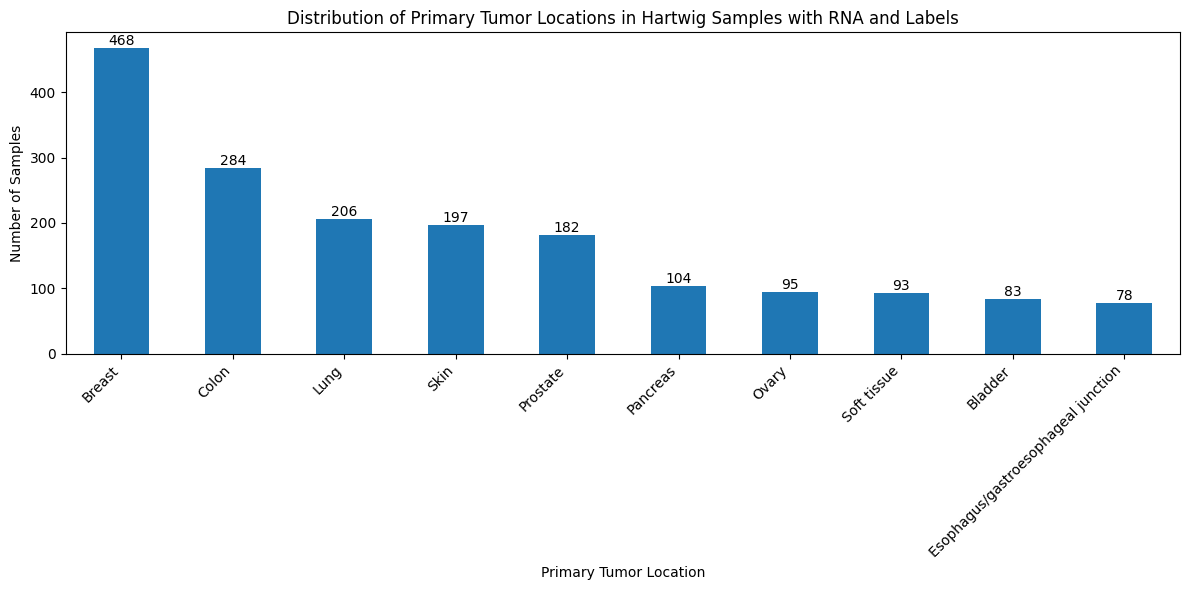

In [48]:
# Plot histogram of cancer organ types from filtered metadata

import matplotlib.pyplot as plt
location_counts = filtered_metadata["primaryTumorLocation"].value_counts()
# filter only top 10 locations for better visualization
location_counts = location_counts.head(10)
plt.figure(figsize=(12, 6))
location_counts.plot(kind="bar")
# print the counts on top of the bars
for index, value in enumerate(location_counts):
    plt.text(index, value, str(value), ha="center", va="bottom")
plt.title("Distribution of Primary Tumor Locations in Hartwig Samples with RNA and Labels")
plt.xlabel("Primary Tumor Location")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [29]:
lung_metadata_df = filtered_metadata[filtered_metadata["primaryTumorLocation"] == "Lung"]
lung_metadata_df["primaryTumorType"].value_counts()

primaryTumorType
Non-small cell carcinoma (NSCLC), not otherwise specified                98
Non-small cell carcinoma (NSCLC), adenocarcinoma                         62
Small cell carcinoma (SCLC)                                              31
Non-small cell carcinoma (NSCLC), squamous cell carcinoma                 5
Neuroendocrine tumor (atypical carcinoid)                                 3
Other                                                                     3
Non-small cell carcinoma (NSCLC), large cell neuroendocrine carcinoma     2
Unknown                                                                   2
Name: count, dtype: int64

#### Investigate multiple samples per patient

In [8]:
# How many unique patientIds in filtered sample metadata?
filtered_metadata["patientId"].value_counts()

2153

In [10]:
# Print the value counts of patients over 1
len(filtered_metadata["patientId"].value_counts()[filtered_metadata["patientId"].value_counts() > 1])

73

In [11]:
# How many samples don't have primaryTumorLocation?
missing_location = filtered_metadata["primaryTumorLocation"].isna().sum()
print(f"Samples missing primaryTumorLocation: {missing_location} out of {len(filtered_metadata)}")

Samples missing primaryTumorLocation: 0 out of 2232


In [36]:
# Save sample_to_cancer, sample_to_organ 
sample_to_cancer = load_pickle("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/sample_to_cancer_mapping.pkl")
sample_to_organ = load_pickle("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/sample_to_organ_mapping.pkl")

In [50]:
# Filter dicts
filtered_sample_to_cancer = {sid: sample_to_cancer[sid] if sid in sample_to_cancer else "Unknown" for sid in samples_with_rna_and_label}
filtered_sample_to_organ = {sid: sample_to_organ[sid] if sid in sample_to_organ else "Unknown" for sid in samples_with_rna_and_label}

In [51]:
len(set(filtered_metadata["primaryTumorType"].values))

58

In [52]:
print(f"Number of cancer types in filtered data: {len(set(filtered_sample_to_cancer.values()))}")
print(f"Number of organs in filtered data: {len(set(filtered_sample_to_organ.values()))}")

Number of cancer types in filtered data: 19
Number of organs in filtered data: 46


In [67]:
# Drug information

# Load the treatment data
treatment_path = '/data/rbg/shared/datasets/Hartwig/isofox_tpm_update_4/treatment_responses.tsv'
df_treat = pd.read_csv(treatment_path, sep='\t')

# 1. Filter using your existing sampleIds set
# Ensure we only look at rows matching your RNA-eligible samples
df_filtered = df_treat[df_treat['sampleId'].isin(adata.obs_names)].copy()


# 2. Calculate Comprehensive Stats
stats = {
    "Samples with Treatment Info": df_filtered['sampleId'].nunique(),
    "Unique Patients": df_filtered['patientId'].nunique(),
    "Unique Drug Names": df_filtered['name'].nunique(),
    "Unique Drug Types": df_filtered['type'].nunique(),
    "Unique Mechanisms": df_filtered['mechanism'].nunique(),
    "Total Treatment Records": len(df_filtered)
}

# 3. Display Results
print("--- Hartwig Cohort Treatment Stats ---")
for k, v in stats.items():
    print(f"{k:30}: {v}")

print("\n--- Top 5 Drug Types ---")
print(df_filtered['type'].value_counts().head(5))

print("\n--- Response Summary (per treatment) ---")
print(df_filtered['response'].value_counts(dropna=False))

# Optional: Check for samples missing treatment info
missing_count = len(samples_with_rna_and_label) - df_filtered['sampleId'].nunique()
if missing_count > 0:
    print(f"\nNote: {missing_count} samples from your set have no entries in the treatment TSV.")

--- Hartwig Cohort Treatment Stats ---
Samples with Treatment Info   : 2631
Unique Patients               : 2511
Unique Drug Names             : 509
Unique Drug Types             : 11
Unique Mechanisms             : 45
Total Treatment Records       : 7858

--- Top 5 Drug Types ---
type
Immunotherapy       2120
Chemotherapy        1795
Multiple therapy    1729
Targeted therapy    1160
Hormonal therapy     526
Name: count, dtype: int64

--- Response Summary (per treatment) ---
response
PR                                                          2488
SD                                                          2200
PD                                                          2068
NaN                                                          605
CR                                                           317
Non-CR/Non-PD                                                 45
ND                                                            38
Clinical progression                                    

In [64]:
len(adata)

2644

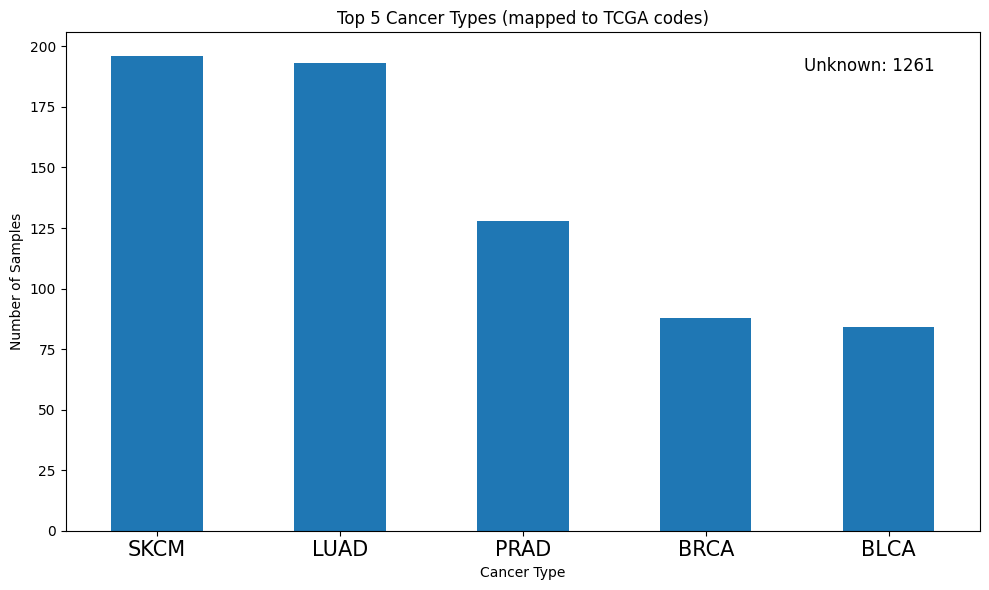

In [61]:
# Plot histogram of cancer types, sort by count and show top 10. only show non "Unknown"
import matplotlib.pyplot as plt
cancer_counts = pd.Series(filtered_sample_to_cancer).value_counts()
filtered_cancer_counts = cancer_counts[cancer_counts.index != "Unknown"].sort_values(ascending=False)
unknown_count = cancer_counts.get("Unknown", 0)
plt.figure(figsize=(10, 6))
filtered_cancer_counts.head(5).plot(kind="bar")
plt.title("Top 5 Cancer Types (mapped to TCGA codes)")
# put unknown count on plot top right
plt.text(0.95, 0.95, f"Unknown: {unknown_count}", transform=plt.gca().transAxes, ha="right", va="top", fontsize=12)
plt.xlabel("Cancer Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0, fontsize=15)
plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
from collections import Counter
cancer_counts = Counter(filtered_sample_to_cancer.values())
plt.figure(figsize=(12, 6))
plt.bar(cancer_counts.keys(), cancer_counts.values())
plt.xticks()
plt.title("Distribution of Cancer Types in Filtered Hartwig Data")
plt.xlabel("Cancer Type")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

### Get cancer types from metadata

In [32]:
cancer_mapping = {
    "ACC":0,"BLCA":1,"BRCA":2,"CESC":3,"CHOL":4,"COAD":5,"DLBC":6,"ESCA":7,
    "GBM":8,"HNSC":9,"KICH":10,"KIRC":11,"KIRP":12,"LAML":13,"LGG":14,
    "LIHC":15,"LUAD":16,"LUSC":17,"MESO":18,"OV":19,"PAAD":20,"PCPG":21,
    "PRAD":22,"READ":23,"SARC":24,"SKCM":25,"STAD":26,"TGCT":27,"THCA":28,
    "THYM":29,"UCEC":30,"UCS":31,"UVM":32
}

hartwig_to_tcga = load_pickle("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/hartwig_to_tcga_cancer_mapping.pkl")

In [33]:
def build_cancer_and_organ_dicts(metadata_path):

    print("Loading:", metadata_path)
    df = pd.read_csv(metadata_path, sep="\t")

    print("Total rows:", len(df))
    print("Unique sampleIds:", df["sampleId"].nunique())

    # Drop rows without sampleId
    df = df.dropna(subset=["sampleId"])

    sample_to_cancer = {}
    sample_to_organ = {}

    unmapped = set()

    for _, row in df.iterrows():
        sid = row["sampleId"]
        tumor_type = row["primaryTumorType"]
        organ = row["primaryTumorLocation"]

        # Map to TCGA csncer type code
        tcga_code = hartwig_to_tcga.get(tumor_type)

        if tcga_code is None:
            unmapped.add(tumor_type)
        else:
            sample_to_cancer[sid] = tcga_code

        # Organ mapping (just raw string)
        if pd.notna(organ):
            sample_to_organ[sid] = organ

    print("Samples mapped to TCGA cancer codes:", len(sample_to_cancer))
    print("Samples mapped to organ:", len(sample_to_organ))

    if len(unmapped) > 0:
        print("\nUnmapped tumor types:")
        for t in unmapped:
            print("-", t)

    return sample_to_cancer, sample_to_organ


In [34]:
metadata_path = "/data/rbg/shared/datasets/Hartwig/isofox_tpm_update_4/metadata.tsv"

sample_to_cancer, sample_to_organ = build_cancer_and_organ_dicts(metadata_path)

print("\nExample cancer mappings:")
print(list(sample_to_cancer.items())[:5])

print("\nExample organ mappings:")
print(list(sample_to_organ.items())[:5])

Loading: /data/rbg/shared/datasets/Hartwig/isofox_tpm_update_4/metadata.tsv
Total rows: 12167
Unique sampleIds: 12167
Samples mapped to TCGA cancer codes: 6565
Samples mapped to organ: 12148

Unmapped tumor types (review needed):
- Unknown
- Urachal carcinoma
- Follicular dendritic cell sarcoma
- nan
- Rhabdomyosarcoma, embryonal
- Epithelioid hemangioendothelioma
- Other
- Rhabdomyosarcoma, spindle cell/sclerosing
- Clear cell carcinoma
- Carcinosarcoma
- Poorly differentiated carcinoma
- Rhabdomyosarcoma, pleomorphic
- Rhabdomyosarcoma, alveolar
- Undifferentiated carcinoma
- Granulosa cell tumor
- Carcinoma
- Rhabdomyosarcoma, not otherwise specified
- Basal cell carcinoma

Example cancer mappings:
[('H00000026', 'SARC'), ('H00000027', 'PAAD'), ('H00000030', 'BRCA'), ('H00000032', 'SARC'), ('H00000041', 'BRCA')]

Example organ mappings:
[('H00000026', 'Soft tissue'), ('H00000027', 'Small bowel/intestine'), ('H00000030', 'Breast'), ('H00000032', 'Soft tissue'), ('H00000033', 'Kidney'

In [35]:
patients_without_cancer_type = set()
for sid in hartwig_patients:
    if sid not in sample_to_cancer:
        patients_without_cancer_type.add(sid)
len(patients_without_cancer_type)

1388

In [109]:
clinical_df[clinical_df["sampleId"] == 'H00000026']

,patientId,sampleId,responseDate,response,startDate,endDate,name,type,mechanism
102,D00000057,H00000026,2016-04-28,PR,2016-02-10,2016-08-17,Regorafenib,Targeted therapy,Multikinase inhibitor


In [110]:
metadata_df = pd.read_csv("/data/rbg/shared/datasets/Hartwig/isofox_tpm_update_4/metadata.tsv", sep="\t")

In [111]:
missing_cancers = {}
for sid in patients_without_cancer_type:
    cancer = metadata_df[metadata_df["sampleId"] == sid]["primaryTumorType"].iloc[0]
    if cancer in missing_cancers:
        missing_cancers[cancer] += 1
    else:
        missing_cancers[cancer] = 1
missing_cancers



{'Unknown': 46,
 'Other': 22,
 'Undifferentiated carcinoma': 5,
 'Carcinoma': 1,
 'Carcinosarcoma': 2,
 'Follicular dendritic cell sarcoma': 1,
 'Basal cell carcinoma': 1,
 'Urachal carcinoma': 1}

In [113]:
# Save sample_to_cancer, sample_to_organ 
pickle_data(sample_to_cancer, "/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/sample_to_cancer_mapping.pkl")
pickle_data(sample_to_organ, "/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/Hartwig/sample_to_organ_mapping.pkl")

### Analyze processed Hartwig embeddings

In [19]:
embeddings = load_pickle("/data/rbg/users/ashyamal/RNA-FM-benchmarking/data/RNA_embeddings/Hartwig_processed.pkl")

In [20]:
list(embeddings.keys())[:5]

['H00009590', 'H00009592', 'H00009593', 'H00009596', 'H00009597']

In [23]:
embeddings["H00009590"].keys()

dict_keys(['RNA_seq', 'max_AURORA', 'max_immuno', 'max_hallmark', 'max_combined', 'mean_AURORA', 'mean_immuno', 'mean_hallmark', 'mean_combined', 'ssGSEA_AURORA', 'ssGSEA_immuno', 'ssGSEA_hallmark', 'ssGSEA_combined', 'scGPT', 'STATE', 'CancerFoundation', 'BulkFormer', 'BulkRNABert', 'COMPASS', 'dataset', 'cancer_type', 'organ', 'PFS_time', 'PFS_event', 'response', 'treatment'])

In [24]:
time_count, event_count, response_count, treatment_count = 0, 0, 0, 0
for sid in embeddings.keys():
    emb = embeddings[sid]
    time, event, response, treatment = emb["PFS_time"], emb["PFS_event"], emb["response"], emb["treatment"]
    if time is not None:
        time_count += 1
    if event is not None:
        event_count += 1
    if response is not None:
        response_count += 1
    if treatment is not None:
        treatment_count += 1
print(f"Samples with time: {time_count}")
print(f"Samples with event: {event_count}")
print(f"Samples with response: {response_count}")
print(f"Samples with treatment: {treatment_count}")

Samples with time: 2232
Samples with event: 2232
Samples with response: 2232
Samples with treatment: 2232


### Examine splits

In [3]:
example_split = load_pickle("../../splits/Hartwig/split_0.pkl")

In [5]:
train_keys, val_keys, test_keys = example_split['train'], example_split['val'], example_split['test']

In [6]:
assert len(set(train_keys).intersection(set(val_keys))) == 0
assert len(set(train_keys).intersection(set(test_keys))) == 0
assert len(set(val_keys).intersection(set(test_keys))) == 0